# The score, the null model and the interval: judging a prediction held out by site

**Level 2: The method in practice** · Needs: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts · Reading time: about 30 minutes

## Objectives

A number such as "R2 = 0.94" means nothing until the statistic is named, a baseline is beside it and the uncertainty is stated. This notebook defines the three things the product reports with every score and then applies the pre-declared criterion that decides whether the learned tier generalises across sites.

By the end you will have:

- scored a learned arm held out by site with two named statistics and put the null model beside it;
- built a 95 percent interval that resamples blasts and one that resamples sites, and seen how much wider the honest one is;
- applied the kill criterion to the arms run here and reproduced the committed verdict on both row sets.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

This cell imports nothing from the notebook yet: it reads the installed versions from the package metadata and prints them, so the output records exactly which engine produced every number below.

In [1]:
# Print the installed version of every package this notebook uses
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.3
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The committed leave-one-site-out scores, intervals and verdict | this repository (MIT), written by the offline bake | the product's own licence | `data/derived/benchmark.json`, fields `protocols` and `verdict` |

## Method

**The statistic.** Two quantities carry the name R2 in this literature. The engine reports both, each under its own name:

- `pearson_r2`, the squared correlation of predicted against measured;
- `r2_identity = 1 - sum((measured - predicted)^2) / sum((measured - mean(measured))^2)`, the variance explained about the identity line, which is negative when the predictions are worse than the mean.

On the 12 published hold-out blasts of Kulatilake, Hudaverdi and Wu 2012 (https://doi.org/10.1007/s10706-012-9496-3) the two differ by a factor of two and a half for the same predictions.

**The null.** A model that predicts the mean measured size of its training rows, using no input. It is fitted inside every fold, as it must be.

**The interval.** A bootstrap that resamples the unit of independence. Under a protocol that holds out sites the unit is the site (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

**The criterion**, declared in the engine before the run: the learned tier counts as generalising across sites only if the best learned arm's `r2_identity` under leave-one-site-out is both positive and at least 0.10 above the null's.

### Step 1: leave one site out for the null and three learned arms

The cell trains each arm on nine sites, predicts the tenth, and collects the out-of-fold predictions of all 97 blasts. The learned arms here are the gradient-boosting, random-forest and stacking arms; the whole ladder of fourteen arms is run in the next topic. The factories `default_arms` returns are used, so each fold gets a fresh model.

In [2]:
# Imports, then out-of-fold predictions for the null and three learned arms
import hashlib
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
loso = benchmark["protocols"]["leave-one-site-out"]["arms"]
factories = bf.default_arms()
names = ["null", "xgboost", "random-forest", "stacking"]
tested, predictions = [], {n: [] for n in names}
for split in bf.leave_one_site_out(train):
    tested += list(split.test)
    for name in names:
        predictions[name] += factories[name]().fit(split.train).predict(split.test)
print("out-of-fold blasts:", len(tested), "| arms:", names)

out-of-fold blasts: 97 | arms: ['null', 'xgboost', 'random-forest', 'stacking']


### Step 2: two statistics, and the null beside them

For each arm the cell prints `pearson_r2` and `r2_identity` on all 97 blasts. The null's `r2_identity` is the baseline: an arm that does not beat it has learned nothing that transfers.

In [3]:
# Both statistics per arm, and whether they equal the committed values
print(f"{'arm':<16}{'Pearson r2':>12}{'r2 identity':>14}{'RMSE (m)':>10}  equals committed")
scores = {}
for name in names:
    s = bf.score(tested, predictions[name], method=name)
    scores[name] = s
    want = loso[name]["supports"]["all"]["score"]["r2_identity"]
    pearson = f"{s.pearson_r2:.4f}" if s.pearson_r2 is not None else "-"
    print(f"{name:<16}{pearson:>12}{s.r2_identity:>14.4f}{s.rmse_m:>10.4f}  {abs(s.r2_identity - want) < 1e-9}")

arm               Pearson r2   r2 identity  RMSE (m)  equals committed
null                  0.6268       -0.2163    0.2067  True
xgboost               0.1633       -0.0342    0.1906  True
random-forest         0.1034       -0.2315    0.2080  True
stacking              0.1644       -0.0345    0.1906  True


### Step 3: why the null needs a second look

The null is the training mean, and the training mean moves when a site is held out: holding out a coarse site lowers it, holding out a fine one raises it. The cell correlates the null's out-of-fold predictions with the measurements. A strongly negative correlation means that any arm that merely tracks the training mean looks "better than the null" without skill.

In [4]:
# Correlation of the null's out-of-fold predictions with the measurements, and the committed value
measured = np.array([b.x50_m for b in tested])
null_values = np.array([p.x50_m for p in predictions["null"]])
r = np.corrcoef(measured, null_values)[0, 1]
print(f"correlation of the null with the measurements = {r:.4f}")
print(f"committed: {benchmark['verdict']['null_pearson_r']:.4f}")

correlation of the null with the measurements = -0.7917
committed: -0.7917


### Step 4: the interval, resampling blasts and resampling sites

`bootstrap_interval` takes a `unit`. With `unit="blast"` each draw resamples the 97 rows with replacement; with `unit="site"` it resamples the ten campaigns, taking each with all its rows. The cell computes both for the gradient-boosting arm with 2000 draws and the benchmark's seed, and compares the site interval with the committed one.

unit = blast  r2_identity -0.0342   95 %: -0.382 to 0.208   width 0.591
unit = site   r2_identity -0.0342   95 %: -2.232 to 0.418   width 2.650
site interval equals the committed one: True


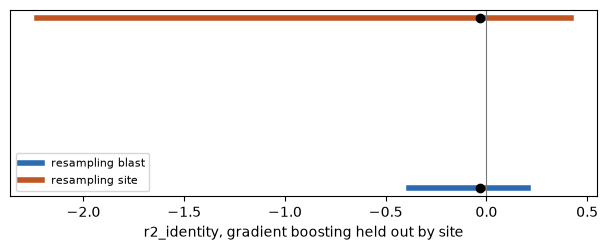

In [5]:
# 95 percent intervals for the gradient-boosting arm under the two resampling units
intervals = {}
for unit in ("blast", "site"):
    point, low, high = bf.bootstrap_interval(tested, predictions["xgboost"], "r2_identity", n_boot=2000, unit=unit, seed=0)
    intervals[unit] = (point, low, high)
    print(f"unit = {unit:<6} r2_identity {point:.4f}   95 %: {low:.3f} to {high:.3f}   width {high - low:.3f}")
want = loso["xgboost"]["supports"]["all"]["interval_95"]
print("site interval equals the committed one:", abs(intervals["site"][1] - want[0]) < 1e-9 and abs(intervals["site"][2] - want[1]) < 1e-9)

fig, ax = plt.subplots(figsize=(6.2, 2.6))
for row, (unit, (point, low, high)) in enumerate(intervals.items()):
    ax.plot([low, high], [row, row], lw=4, color="#2b6cb0" if unit == "blast" else "#c05621", label=f"resampling {unit}")
    ax.plot([point], [row], "o", color="black")
ax.axvline(0, color="#777", lw=0.8)
ax.set_yticks([])
ax.set_xlabel("r2_identity, gradient boosting held out by site")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Step 5: apply the criterion on both row sets

The classical arms can only answer where a geometry exists, so the engine reports every grouped score on two row sets: `all` (97 blasts) and `geometry` (91; `SUPPORTS` holds both predicates). The cell takes the best of the three learned arms on each row set, compares it with the null on the same rows, applies the two halves of the criterion, and compares with the committed verdict. Because only three of the six learned arms are run here, the verdict is checked against the committed best arm, which is among them.

In [6]:
# The kill criterion on each row set: best learned arm, margin over the null, both halves, and the committed verdict
print(bf.KILL_CRITERION[:140], "...")
print("same text as the committed benchmark:", bf.KILL_CRITERION == benchmark["kill_criterion"], "| sha256", hashlib.sha256(bf.KILL_CRITERION.encode()).hexdigest()[:16])
learned = ["xgboost", "random-forest", "stacking"]
print(f"{'rows':<10}{'n':>4}{'best learned':>18}{'r2':>9}{'null r2':>11}{'margin':>9}  {'positive':>9}{'>= 0.10':>9}  met  committed")
for support, keep in bf.SUPPORTS.items():
    rows = [i for i, b in enumerate(tested) if keep(b)]
    chosen = [tested[i] for i in rows]
    r2 = {n: bf.score(chosen, [predictions[n][i] for i in rows]).r2_identity for n in [*learned, 'null']}
    best = max(learned, key=r2.get)
    margin = r2[best] - r2['null']
    met = r2[best] > 0 and margin >= 0.10
    want = benchmark["verdict"]["supports"][support]
    print(f"{support:<10}{len(rows):>4}{best:>18}{r2[best]:>9.4f}{r2['null']:>11.4f}{margin:>9.4f}  {str(r2[best] > 0):>9}{str(margin >= 0.10):>9}  {str(met):<6}  {want['best_learned_arm']} {want['generalises_across_sites']}")

The learned tier counts as generalising across sites only if the best learned arm's variance explained under leave-one-site-out is BOTH posi ...
same text as the committed benchmark: True | sha256 a13f11385ef810ec
rows         n      best learned       r2    null r2   margin   positive  >= 0.10  met  committed
all         97           xgboost  -0.0342    -0.2163   0.1821      False     True  False   xgboost False
geometry    91          stacking   0.0343    -0.2320   0.2663       True     True  True    stacking True


## Results

**The score is only meaningful beside its baseline.** Held out by site, the null scores a clearly negative variance explained (about -0.22), the random forest is about as bad, and gradient boosting and stacking land just below zero: none of them beats a constant equal to the overall mean of the measurements, which scores zero. The notebook's numbers equal the committed benchmark to the last digit.

**The null is not a neutral baseline.** Its out-of-fold predictions correlate strongly and negatively with the measurements, because holding out a coarse site lowers the training mean. So a margin over the null is easy to obtain without skill, which is why the criterion requires a positive score as well as a margin.

**The honest interval is much wider.** Resampling blasts treats the 97 rows as independent and gives a tight interval around the point; resampling sites, the unit that is actually independent, gives an interval several times wider that spans zero. With ten campaigns, no learned arm can claim a score above zero.

**The verdict depends on the row set.** Over all 97 blasts the best learned arm is negative and the criterion is not met. Over the 91 blasts with a geometry the best arm is slightly positive and more than 0.10 above a null that is itself negative, and the criterion is met. The six blasts that separate the two sets are all from one campaign, and the product reports the verdict both ways rather than choosing one.

**What this does not show.** Meeting the criterion on 91 blasts does not make the learned arms good: the point score is near zero and the interval spans it. The criterion is a minimum for "generalises", not a certificate of skill.

## Summary

- Report two named statistics, a null fitted inside every fold, and an interval that resamples sites.
- The null's predictions correlate negatively with the data, so a margin alone is not skill; the criterion needs a positive score as well.
- The verdict is not met over 97 blasts and met over 91, and the engine reports both.
- Next: notebook 03 checks a published score against the distribution of its own protocol (level 3).

## References

- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (resampling the independent unit)
- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the 12-blast hold-out where two statistics share a name)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/